In [1]:
import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import pandas as pd

st_data = ad.read_h5ad('/work/magroup/skrieger/Syndri/data/datasets/agingbrain_merfish/raw/spatial/c93d78c2-ee17-4504-8d1c-17cf093ad7b5.h5ad')

In [4]:
combos = st_data.obs[['age','donor_id','slice']].drop_duplicates()
unique = combos.groupby(['age','donor_id'])['slice'].nunique()
unique[unique!=0]

/tmp/ipykernel_3074427/312131177.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  unique = combos.groupby(['age','donor_id'])['slice'].nunique()


age   donor_id                   
4wk   MsBrainAgingSpatialDonor_1     1
      MsBrainAgingSpatialDonor_4     3
      MsBrainAgingSpatialDonor_7     3
      MsBrainAgingSpatialDonor_8     3
24wk  MsBrainAgingSpatialDonor_10    3
      MsBrainAgingSpatialDonor_11    3
      MsBrainAgingSpatialDonor_12    2
90wk  MsBrainAgingSpatialDonor_2     2
      MsBrainAgingSpatialDonor_3     2
      MsBrainAgingSpatialDonor_5     3
      MsBrainAgingSpatialDonor_6     3
      MsBrainAgingSpatialDonor_9     3
Name: slice, dtype: int64

In [7]:
st_data.obs[['center_x','center_y']] = st_data.obs[['center_x','center_y']].astype(float)

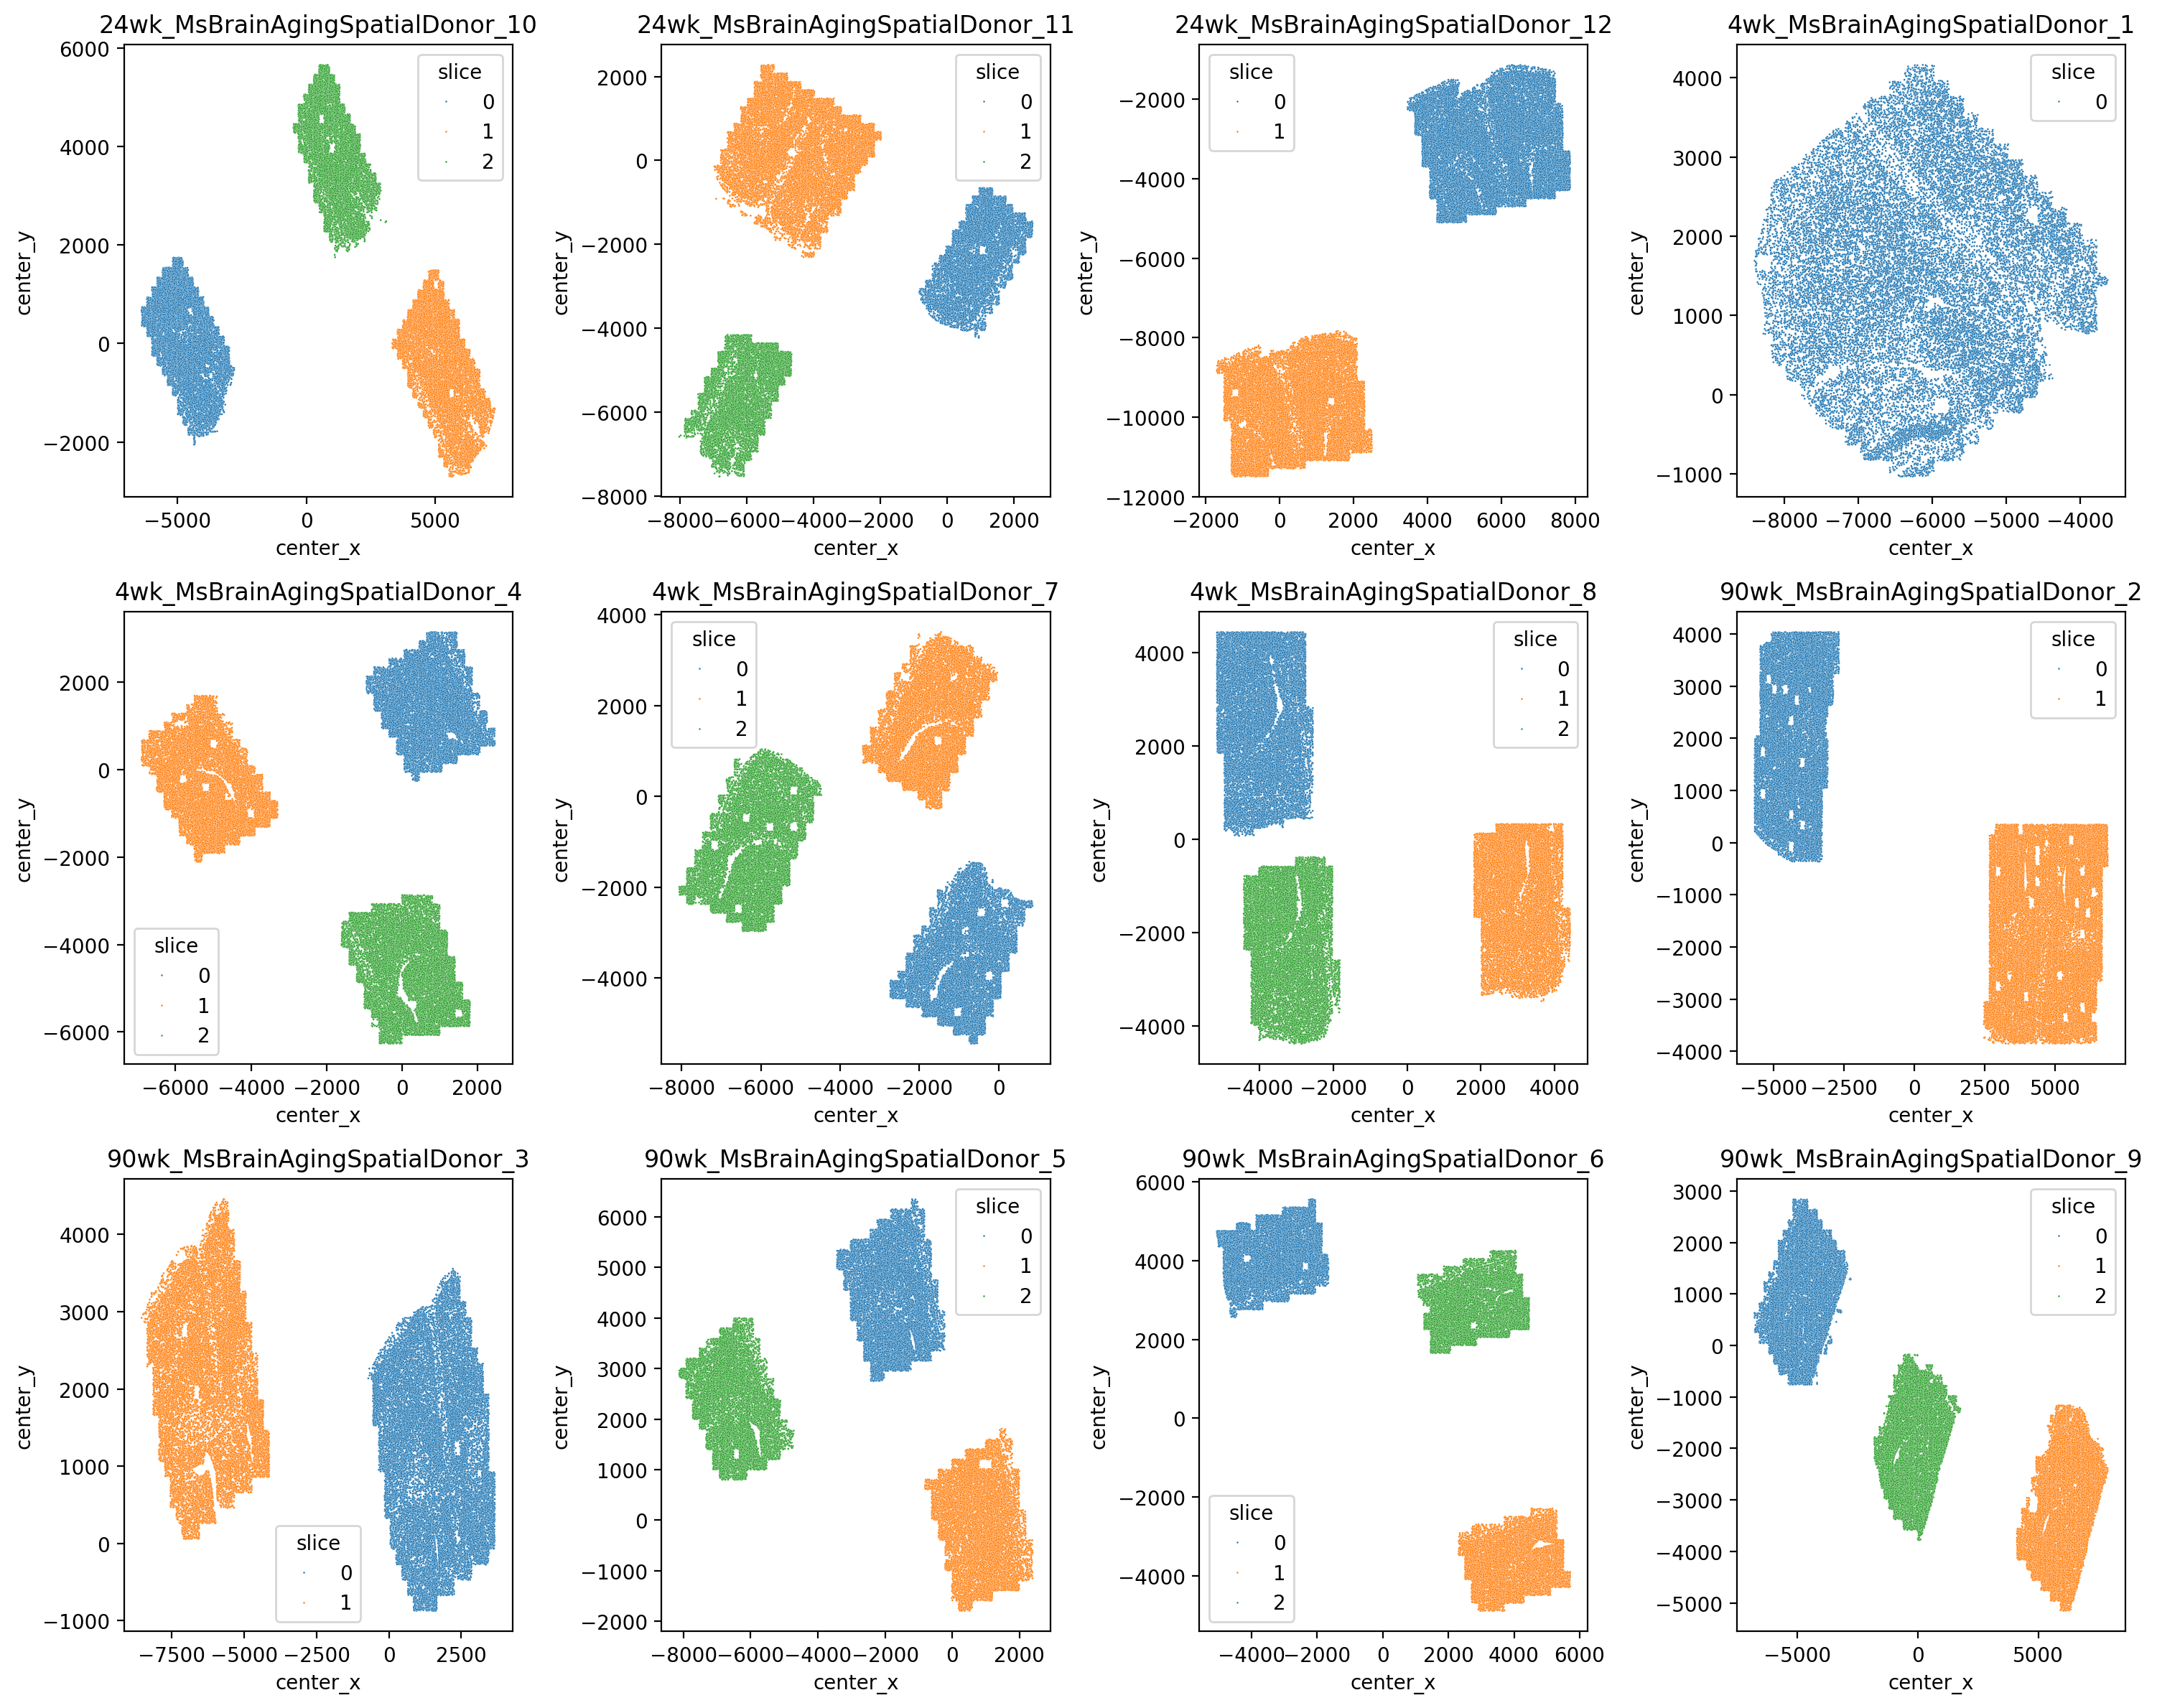

In [17]:
st_data.obs['cond_label'] = st_data.obs['age'].astype(str) + '_' + st_data.obs['donor_id'].astype(str)
labels = sorted(st_data.obs['cond_label'].unique().tolist())
fig,axes = plt.subplots(nrows=3,ncols=4,figsize=(15,12),dpi=200)

for i,ax in enumerate(axes.flat):
    plot_data = st_data[st_data.obs['cond_label']==labels[i]]
    sns.scatterplot(x=plot_data.obs['center_x'],y=plot_data.obs['center_y'],hue=plot_data.obs['slice'],ax=ax,s=1,palette='tab10')
    ax.set_title(labels[i])

fig.tight_layout()



/tmp/ipykernel_3074427/1849452506.py:6: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  trainset.obs['split'] = 'train'


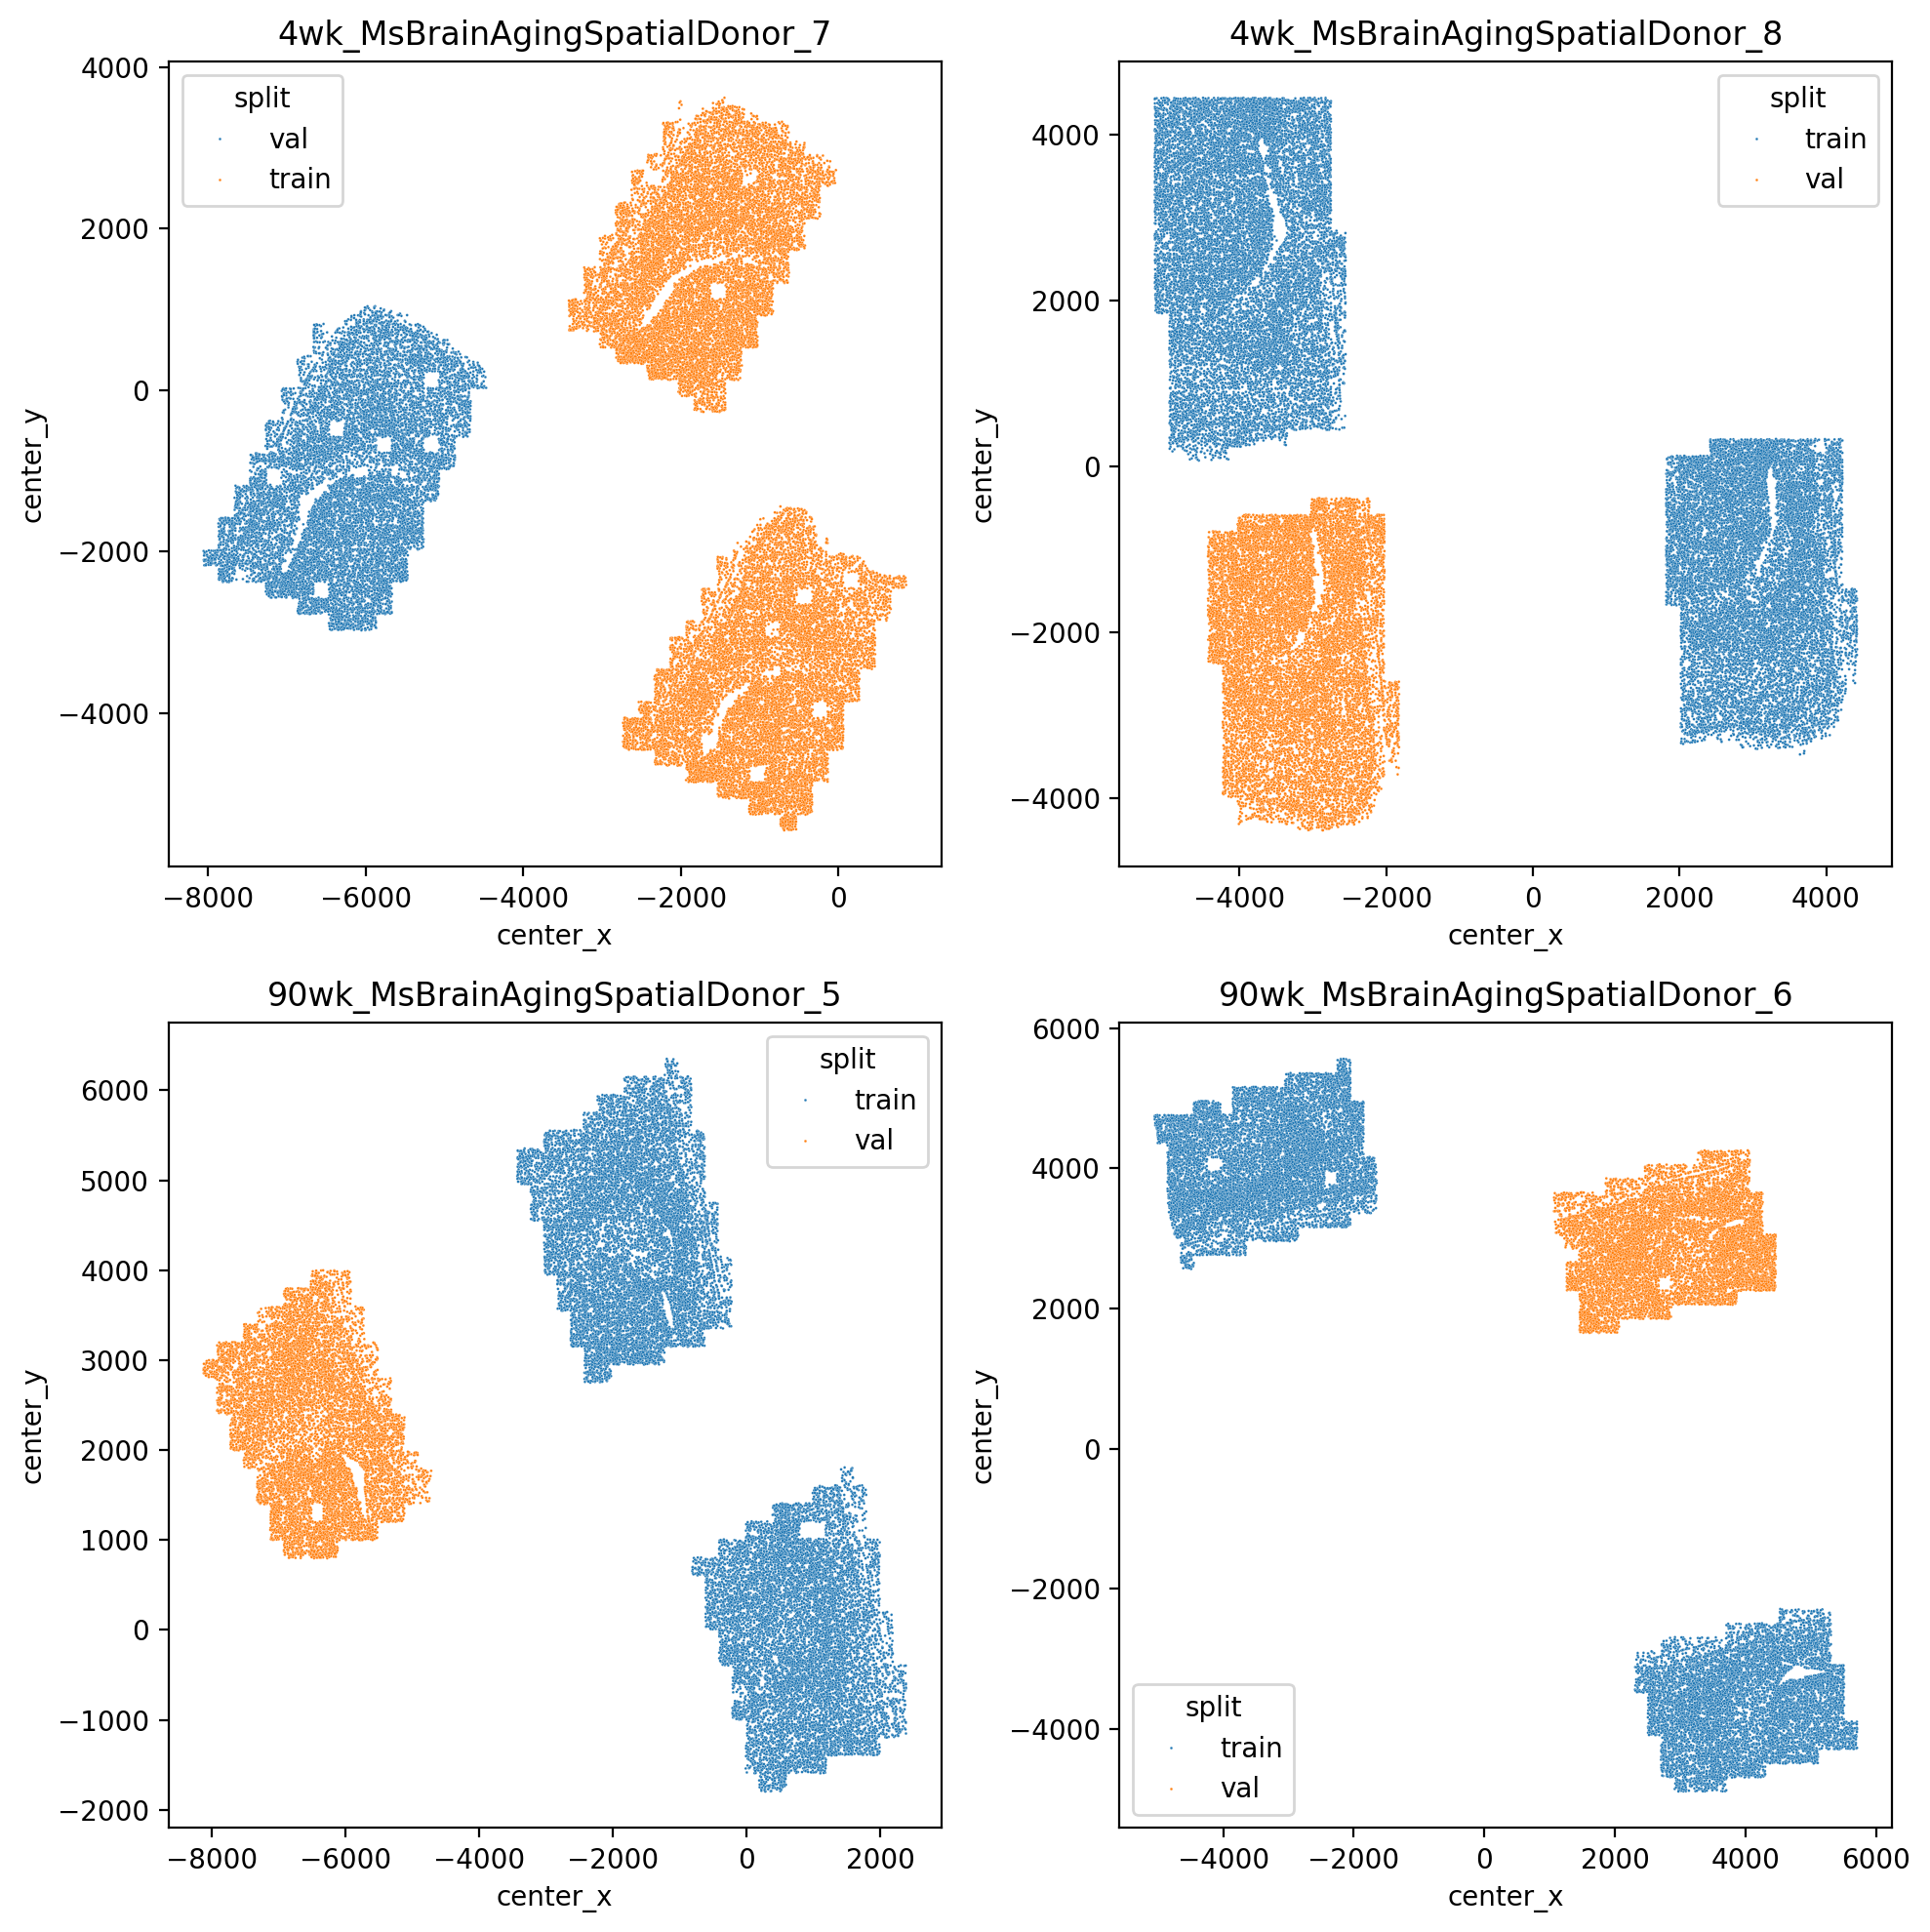

In [28]:
st_data.obs['cond_label'] = st_data.obs['age'].astype(str) + '_' + st_data.obs['donor_id'].astype(str)
labels = sorted(st_data.obs['cond_label'].unique().tolist())
trainset= st_data[st_data.obs['donor_id'].str.contains('Donor_5|Donor_6|Donor_7|Donor_8')]
labels = sorted(trainset.obs['cond_label'].unique().tolist())
fig,axes = plt.subplots(nrows=2,ncols=2,figsize=(10,10),dpi=200)
trainset.obs['split'] = 'train'
trainset.obs.loc[trainset.obs['slice']=='2','split'] = 'val'
for i,ax in enumerate(axes.flat):
    plot_data = trainset[trainset.obs['cond_label']==labels[i]]
    sns.scatterplot(x=plot_data.obs['center_x'],y=plot_data.obs['center_y'],hue=plot_data.obs['split'],ax=ax,s=1,palette='tab10')
    ax.set_title(labels[i])

fig.tight_layout()

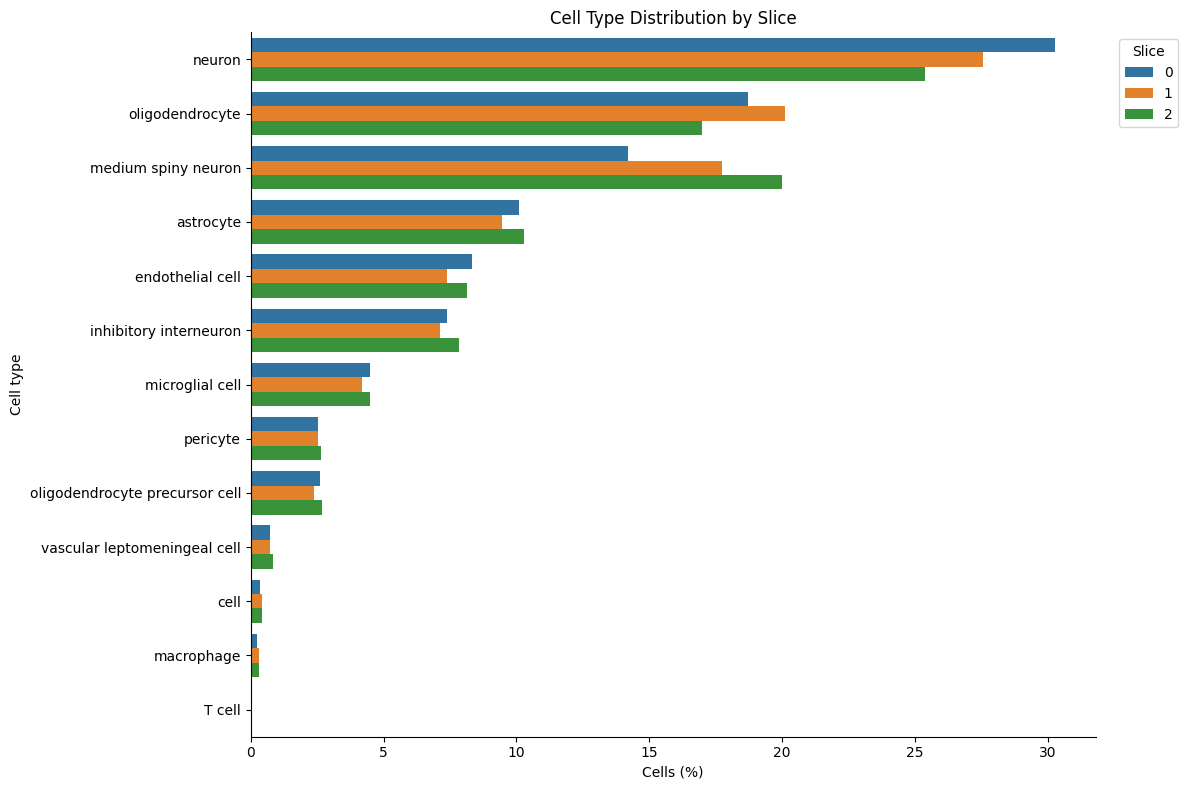

In [3]:
plt.figure(figsize=(12, 8))

sns.barplot(
    data=cell_type_dist,
    x="percentage",
    y=cell_type_col,
    hue="slice",
    order=cell_type_order,
)

plt.xlabel("Cells (%)")
plt.ylabel("Cell type")
plt.title("Cell Type Distribution by Slice")
plt.legend(title="Slice", bbox_to_anchor=(1.02, 1), loc="upper left")

sns.despine()
plt.tight_layout()
plt.show()